In [1]:
import numpy as np
import fastplotlib as fpl
import tifffile

from scipy.sparse.linalg import svds

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

WGPU: enumerate_adapters() is deprecated, use enumerate_adapters_sync() instead.
Unable to find extension: VK_EXT_swapchain_colorspace
WGPU: request_adapter() is deprecated, use request_adapter_sync() instead.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


Available devices:
✅ (default) | AMD RADV POLARIS10 (ACO) | DiscreteGPU | Vulkan | Mesa 20.3.5 (ACO)
❗ | llvmpipe (LLVM 11.0.1, 256 bits) | CPU | Vulkan | Mesa 20.3.5 (LLVM 11.0.1)
✅ | NVIDIA GeForce RTX 3080 | DiscreteGPU | Vulkan | 530.30.02
❗ | Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1) | Unknown | OpenGL | 4.6 (Core Profile) Mesa 20.3.5


To silence this warning, use a fully namespaced name.


In [2]:
sub = tifffile.imread("./sub_filtered.tif")

In [3]:
from sklearn.metrics import pairwise_distances
from tqdm import tqdm

In [4]:
# sub = sub[:, ::2, ::2]
sub.T.shape

(36, 37, 10000)

RFBOutputContext()

WGPU: request_device() is deprecated, use request_device_sync() instead.
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
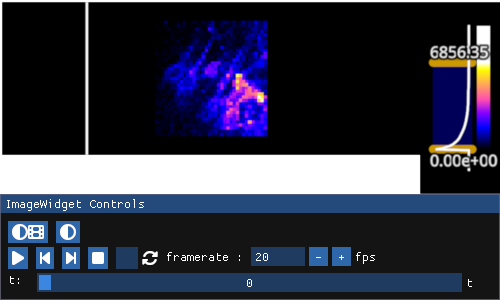

In [5]:
iw_sub = fpl.ImageWidget(sub, cmap="gnuplot2")
iw_sub.show()

In [5]:
3950-80

3870

In [3]:
sub = sub[:, ::3, ::3]

In [4]:
Y = sub.T.reshape(sub.shape[1] * sub.shape[2], sub.shape[0])

In [5]:
Y.shape

(156, 10000)

In [6]:
t = 3940
w2 = 50 * 2
w = int(w2 / 2)

snippet = Y[:, t - w:t + w:]

RFBOutputContext()

WGPU: request_device() is deprecated, use request_device_sync() instead.
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
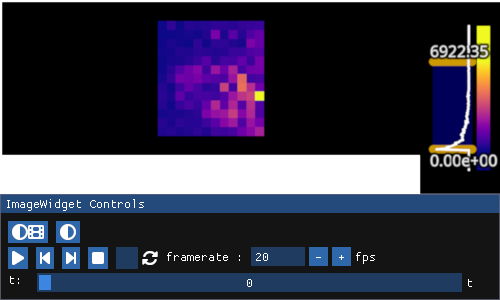

In [10]:
fpl.ImageWidget(snippet.T.reshape(snippet.shape[1], sub.shape[2], sub.shape[1]).swapaxes(1, 2)).show()

In [7]:
covs = np.zeros((w2 - 10, Y.shape[0], Y.shape[0]), dtype=np.float32)

In [8]:
snippet.shape

(156, 100)

In [9]:
for i in range(10, w2 - 10):
    covs[i - 10] = snippet[:, i:i + 10] @ snippet[:, i - 10:i].T
    
    # covs[i - 10] = pairwise_distances(snippet[:, i:i + 10], snippet[:, i - 10:i], metric="correlation")

In [10]:
covs = np.nan_to_num(covs, copy=False)

In [11]:
covs.min(), covs.max()

(np.float32(0.0), np.float32(670866240.0))

In [12]:
covs -= covs.min()
covs /= covs.max()

In [13]:
from ipywidgets import IntSlider, HBox, VBox

In [18]:
iw_cov = fpl.ImageWidget(covs[0], cmap="viridis", histogram_widget=True)
iw_space = fpl.ImageWidget(np.zeros((sub.shape[2], sub.shape[1])).T, cmap="viridis", histogram_widget=True)

selector_cov = iw_cov.managed_graphics[0].add_linear_selector(axis="y")

@selector_cov.add_event_handler("selection")
def update_img(ev):
    ix = ev.get_selected_index()

    space = iw_cov.managed_graphics[0].data[ix].reshape((sub.shape[2], sub.shape[1])).T
    iw_space.set_data(space, reset_vmin_vmax=False)

def update_cov(change):
    ix = change["new"]
    iw_cov.set_data(covs[ix], reset_vmin_vmax=False)
    
    space = iw_cov.managed_graphics[0].data[selector_cov.get_selected_index()].reshape((sub.shape[2], sub.shape[1])).T
    iw_space.set_data(space, reset_vmin_vmax=False)

slider = IntSlider(value=0, min=0, max=snippet.shape[1] - 1, step=1)
slider.observe(update_cov, "value")

VBox([
    HBox([iw_cov.show(), iw_space.show()]),
    slider
])

RFBOutputContext()

RFBOutputContext()

In [17]:
for g in [*iw_cov.managed_graphics, *iw_space.managed_graphics]:
    g.vmin, g.vmax = 0, 1

NameError: name 'iw_cov' is not defined

In [14]:
covs.shape

(90, 156, 156)

In [15]:
covs = covs[:-20]

In [16]:
covs.T.shape

(156, 156, 70)

In [17]:
cc = covs.T.reshape(covs.shape[1] * covs.shape[2], covs.shape[0])

In [18]:
cc.shape

(24336, 70)

In [19]:
cov_cov = cc @ cc.T

In [20]:
cov_cov.shape

(24336, 24336)

In [21]:
iw_cov_cov = fpl.ImageWidget(cov_cov, cmap="viridis", histogram_widget=True)
iw_cov = fpl.ImageWidget(np.zeros((covs[0].shape)), cmap="viridis", histogram_widget=True)
iw_space = fpl.ImageWidget(np.zeros((covs[0].shape)), cmap="viridis", histogram_widget=True)

selector_cov_cov = iw_cov_cov.managed_graphics[0].add_linear_selector(axis="y")
selector_cov = iw_cov.managed_graphics[0].add_linear_selector(axis="y")

@selector_cov_cov.add_event_handler("selection")
def update_cov(ev):
    ix = ev.get_selected_index()

    cov = iw_cov_cov.managed_graphics[0].data[ix].reshape(covs[0].shape)
    iw_cov.set_data(cov, reset_vmin_vmax=False)

@selector_cov.add_event_handler("selection")
def update_img(ev):
    ix = ev.get_selected_index()

    space = iw_cov.managed_graphics[0].data[ix].reshape((sub.shape[2], sub.shape[1])).T
    iw_space.set_data(space, reset_vmin_vmax=False)

VBox([
    HBox([iw_cov_cov.show(), iw_cov.show(), iw_space.show()]),
])

RFBOutputContext()

WGPU: request_device() is deprecated, use request_device_sync() instead.
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

RFBOutputContext()